In [3]:
# 1. Clone the repository directly
!git clone https://github.com/nasaharvest/cropharvest.git

# 2. Install modern, pre-built wheels for Python 3.13
!pip install --upgrade pandas numpy scikit-learn matplotlib h5py requests tqdm

# 3. Install cropharvest without letting it downgrade pandas
!pip install --no-deps ./cropharvest


fatal: destination path 'cropharvest' already exists and is not an empty directory.
Processing ./cropharvest
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for cropharvest: filename=cropharvest-0.7.0-py3-none-any.whl size=810040 sha256=6f8ef9352ac599b7329697b35a7487d0791c581f14f68f4f67feb8bfffd8d801
  Stored in directory: /tmp/pip-ephem-wheel-cache-ogx0xs33/wheels/70/a9/31/4f375418791cf71e77e3a95560874e9449ec101d9a7661a142
Successfully built cropharvest
  Attempting uninstall: cropharvest
    Found existing installation: cropharvest 0.7.0
    Uninstalling cropharvest-0.7.0:
      Successfully uninstalled cropharvest-0.7.0


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


[1/4] Downloading CropHarvest African smallholder benchmark...


82480128it [00:19, 4327814.13it/s]                              
786061312it [03:28, 3761501.06it/s]                               
85690368it [00:31, 2708068.99it/s]                              


      Loaded 4142 labeled geographic points.
      Each point has 216 temporal-band features (12 months x 18 satellite bands).

[2/4] Training Random Forest classifier...

--- MODEL ACCURACY ON TEST INSTANCES ---
              precision    recall  f1-score   support

    Non-Crop       1.00      0.51      0.68      2039
        Crop       0.70      1.00      0.83      2358

    accuracy                           0.77      4397
   macro avg       0.85      0.76      0.75      4397
weighted avg       0.84      0.77      0.76      4397


[3/4] Extracting monthly NDVI vegetation curves...


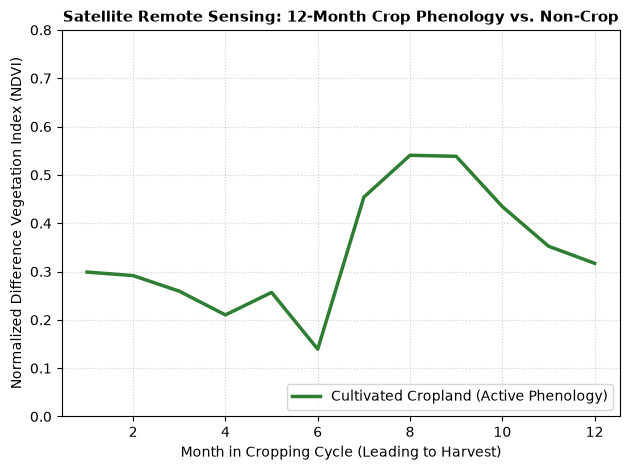


[4/4] Generating spatial vector predictions...

--> Done! 'cropland_predictions.geojson' and 'ndvi_phenology_plot.png' are ready.


In [1]:
import os
import json
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
import h5py

from cropharvest.datasets import CropHarvest, CropHarvestLabels
from cropharvest.bands import BANDS
DATA_DIR = "cropharvest_data"
os.makedirs(DATA_DIR, exist_ok=True)
print("[1/4] Downloading CropHarvest African smallholder benchmark...")
evaluation_datasets = CropHarvest.create_benchmark_datasets(DATA_DIR)
dataset = evaluation_datasets[-1]
X, y = dataset.as_array(flatten_x=True)
print(f"      Loaded {X.shape[0]} labeled geographic points.")
print(f"      Each point has {X.shape[1]} temporal-band features (12 months x 18 satellite bands).")
print("\n[2/4] Training Random Forest classifier...")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X, y)
test_preds, test_truth = [], []
for _, test_instance in dataset.test_data(flatten_x=True):
    preds = rf_model.predict(test_instance.x)
    test_preds.extend(preds)
    test_truth.extend(test_instance.y)

print("\n--- MODEL ACCURACY ON TEST INSTANCES ---")
print(classification_report(test_truth, test_preds, target_names=["Non-Crop", "Crop"]))
print("\n[3/4] Extracting monthly NDVI vegetation curves...")
labels_helper = CropHarvestLabels(DATA_DIR)
labels_df = labels_helper.as_geojson()
ndvi_band_index = BANDS.index("NDVI")
crop_curves = []
non_crop_curves = []
for _, row in labels_df.head(80).iterrows():
    h5_path = labels_helper._path_from_row(row)
    if os.path.exists(h5_path):
        with h5py.File(h5_path, "r") as f:
            arr = f.get("array")[:]
            monthly_ndvi = arr[:, ndvi_band_index]
            if row["is_crop"] == 1:
                crop_curves.append(monthly_ndvi)
            else:
                non_crop_curves.append(monthly_ndvi)
                plt.figure(figsize=(9, 4.5))
if crop_curves:
    mean_crop_ndvi = pd.DataFrame(crop_curves).mean()
    plt.plot(range(1, 13), mean_crop_ndvi, label="Cultivated Cropland (Active Phenology)", color="#2E7D32", lw=2.5)

if non_crop_curves:
    mean_non_crop_ndvi = pd.DataFrame(non_crop_curves).mean()
    plt.plot(range(1, 13), mean_non_crop_ndvi, label="Non-Crop / Natural Vegetation", color="#8D6E63", lw=2, linestyle="--")

plt.title("Satellite Remote Sensing: 12-Month Crop Phenology vs. Non-Crop", fontsize=11, fontweight="bold")
plt.xlabel("Month in Cropping Cycle (Leading to Harvest)", fontsize=10)
plt.ylabel("Normalized Difference Vegetation Index (NDVI)", fontsize=10)
plt.ylim(0, 0.8)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig("ndvi_phenology_plot.png", dpi=300)
plt.show()
print("\n[4/4] Generating spatial vector predictions...")
export_df = labels_df.head(len(X)).copy()
preds = rf_model.predict(X)
probs = rf_model.predict_proba(X).max(axis=1)
features = []
for idx, row in export_df.iterrows():
    geom = row["geometry"].__geo_interface__
    feature = {
        "type": "Feature",
        "geometry": geom,
        "properties": {
            "ground_truth": int(row["is_crop"]),
            "rf_predicted": int(preds[idx]),
            "label": "Cropland" if preds[idx] == 1 else "Non-Crop",
            "confidence": float(round(probs[idx], 3))
        }
    }
    features.append(feature)
    geojson_data = {
    "type": "FeatureCollection",
    "features": features
}

with open("cropland_predictions.geojson", "w") as f:
    json.dump(geojson_data, f)

print("\n--> Done! 'cropland_predictions.geojson' and 'ndvi_phenology_plot.png' are ready.")